# PINZAS 3 — Fuerza de la trampa y forma del pozo, por arrastre

Con una partícula atrapada se mueve la platina. El fluido arrastra a la partícula y la trampa la retiene. Como no hay inercia (número de Reynolds ~10⁻⁴), en todo momento

$$F_\mathrm{trampa}(x) + \gamma\,(v_f - \dot x) = 0 \qquad\Longrightarrow\qquad \frac{F_\mathrm{trampa}(x)}{\gamma} = \dot x - v_f ,$$

con $v_f$ la velocidad del fluido (la de la platina) y $\gamma$ el coeficiente de arrastre de la partícula. **Las dos cosas de la derecha se miden en el video**: cuánto se movió la partícula entre dos cuadros (`seguida.csv`) y cuánto se corrió toda la imagen (`platina.csv`, ver PINZAS 2). No se usa ningún valor del motor.

Lo que sale directo del video es entonces $u(x) = F_\mathrm{trampa}(x)/\gamma$, **en µm/s**: la velocidad con la que la trampa sola movería a la partícula en fluido quieto. Eso da la **forma del pozo** sin suponer nada. Para pasar a pN hace falta $\gamma$, que es lo más incierto de la práctica (sección 5).

**Límite que atraviesa todo:** una patada dura 0.2 a 0.5 s y la cámara toma 10 a 12.5 cuadros por segundo, así que hay 2 a 5 cuadros por patada y la partícula recorre varios µm entre cuadro y cuadro.

Entradas: `datos/<grabación>/seguida.csv`, `fuerza_intervalos.csv` y `patadas.csv` (las escribe PINZAS 2). Salidas: `datos/pinzas/pozo_ajustes.csv`, `pozo_mapa.csv`, `fuerza_resumen.csv` y `figuras/PINZAS 3/`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pinzas_datos import RAIZ, DATOS, CATALOGO, ESCALA_UM
from pinzas_fuerza import fuerza_modelo, avanzar, ajustar_pozo

plt.style.use("seaborn-v0_8")
fs = 14
plt.rcParams.update({"font.family": "serif", "font.size": fs, "axes.labelsize": fs,
                     "xtick.labelsize": fs, "ytick.labelsize": fs, "legend.fontsize": fs,
                     "mathtext.default": "regular", "mathtext.fontset": "cm", "legend.frameon": True})
SERIE1, SERIE2, AJUSTE = "#2A9D8F", "#E76F51", "#264653"
AZUL, VIOLETA = "#4C72B0", "#8172B2"
FIGURAS = os.path.join(RAIZ, "figuras", "PINZAS 3")
os.makedirs(FIGURAS, exist_ok=True)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
KB_T = 1.380649e-23 * 296.15            # J, a 23 °C


def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(os.path.join(FIGURAS, nombre + ".pdf"), bbox_inches="tight")
    fig.savefig(os.path.join(FIGURAS, nombre + ".png"), bbox_inches="tight", dpi=300)


CON_PATADAS = [n for n, v in CATALOGO.items() if v["tipo"] == "patadas"]
leer = lambda nombre, archivo: pd.read_csv(os.path.join(DATOS, nombre, archivo))
inter = pd.concat([leer(n, "fuerza_intervalos.csv") for n in CON_PATADAS], ignore_index=True)
pat = pd.read_csv(os.path.join(DATOS, "pinzas", "patadas.csv"))
seg = {n: leer(n, "seguida.csv") for n in CON_PATADAS}
inter["eje"] = np.where(inter.e_x.abs() >= inter.e_y.abs(), "x", "y")
utiles = pat[pat.confiable & pat.antes]
print("%d patadas confiables con una partícula atrapada al empezar; %d intervalos entre cuadros" % (len(utiles), len(inter)))
utiles.groupby(["grabacion", "resultado"], sort=False).size().unstack(fill_value=0)

130 patadas confiables con una partícula atrapada al empezar; 3498 intervalos entre cuadros


resultado,no se aparto,escapo,se aparto y volvio
grabacion,,,
LASER NE,48,1,0
BARRIDO 1,1,4,7
MUEVO A MANO,2,10,2
BARRIDO 2,3,4,4
BARRIDO STEPSIZE,0,6,0
BARRIDO STEPSIZE 2,1,0,10
BARRIDO STEPSIZE 3,2,9,16


## 1. Una patada, cuadro a cuadro

$\xi$ es la posición de la partícula a lo largo de la dirección de la patada, medida desde el centro de la trampa. Dos patadas de `BARRIDO STEPSIZE 2`: en una la partícula se aparta y vuelve sola; en la otra se escapa. La partícula se sigue con las detecciones de una ventana alrededor de la trampa (`trampa_detecciones.csv`), sin el límite de salto del seguimiento general.

BARRIDO STEPSIZE 2, patada 1: la imagen se corre 8.8 µm en 0.40 s, pico de 42 µm/s por cuadro; la partícula llega a 3.67 µm → se aparto y volvio
BARRIDO STEPSIZE 2, patada 9: la imagen se corre 10.6 µm en 0.40 s, pico de 42 µm/s por cuadro; la partícula llega a 9.13 µm → escapo


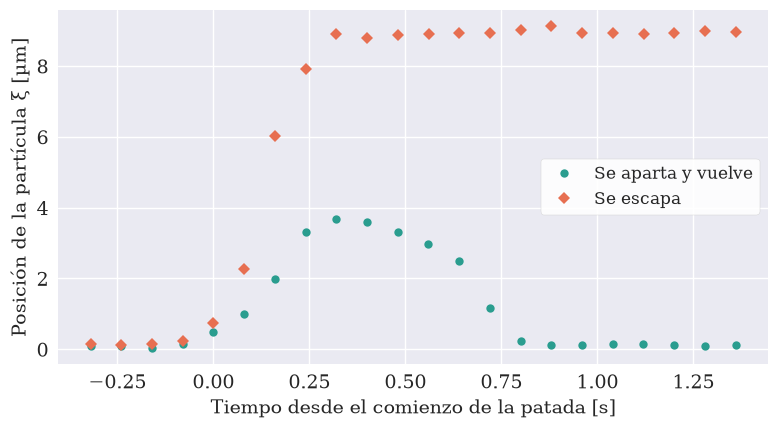

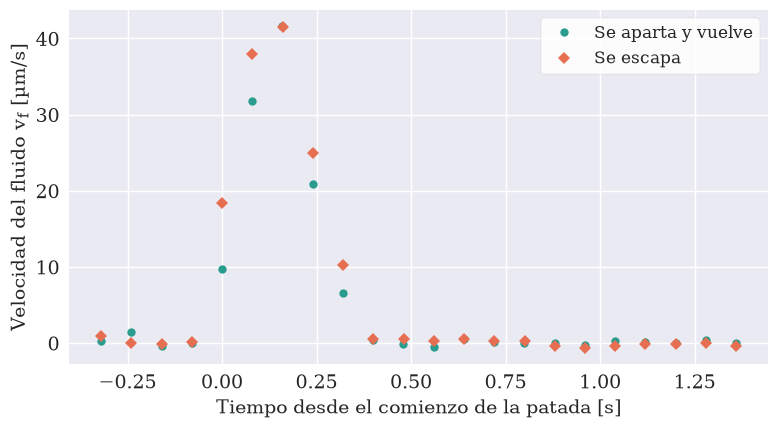

In [2]:
def serie(nombre, n, antes=4, despues=14):
    r = pat[(pat.grabacion == nombre) & (pat.n == n)].iloc[0]
    s = seg[nombre].iloc[r.cuadro_ini - antes:r.cuadro_fin + despues]
    norma = np.hypot(r.dx_um, r.dy_um)
    xi = (s.x_um * r.dx_um + s.y_um * r.dy_um) / norma
    vf = (s.plat_dx_um * r.dx_um + s.plat_dy_um * r.dy_um) / norma / np.median(np.diff(s.t_s))
    return s.t_s.values - r.t_ini_s, xi.values, vf.values, r


ejemplos = (("BARRIDO STEPSIZE 2", 1, SERIE1, "o", "Se aparta y vuelve"), ("BARRIDO STEPSIZE 2", 9, SERIE2, "D", "Se escapa"))
fig, ax = plt.subplots(figsize=(8, 4.5))
for nombre, n, color, fmt, etiqueta in ejemplos:
    t, xi, vf, r = serie(nombre, n)
    ax.plot(t, xi, fmt, ms=6, color=color, mec=color, zorder=3, label=etiqueta)
ax.set_xlabel("Tiempo desde el comienzo de la patada [s]")
ax.set_ylabel(r"Posición de la partícula $\xi$ [µm]")
ax.legend(loc="center right", fontsize=12, facecolor="white", framealpha=0.9)
guardar(fig, "ejemplo_posicion")

fig, ax = plt.subplots(figsize=(8, 4.5))
for nombre, n, color, fmt, etiqueta in ejemplos:
    t, xi, vf, r = serie(nombre, n)
    ax.plot(t, vf, fmt, ms=6, color=color, mec=color, zorder=3, label=etiqueta)
    print("%s, patada %d: la imagen se corre %.1f µm en %.2f s, pico de %.0f µm/s por cuadro; la partícula llega a %.2f µm → %s"
          % (nombre, n, np.hypot(r.dx_um, r.dy_um), r.duracion_s, np.nanmax(vf), r.xi_max_um, r.resultado))
ax.set_xlabel("Tiempo desde el comienzo de la patada [s]")
ax.set_ylabel(r"Velocidad del fluido $v_f$ [µm/s]")
ax.legend(loc="upper right", fontsize=12, facecolor="white", framealpha=0.9)
guardar(fig, "ejemplo_velocidad")

## 2. El mapa de fuerza: $u(\xi) = F/\gamma$

Para cada par de cuadros consecutivos alrededor de una patada: $u = (\Delta\xi - s)/\Delta t$, con $\Delta\xi$ lo que se movió la partícula y $s$ lo que se corrió la imagen, asignado a la posición media de la partícula en el intervalo. Se juntan todas las patadas a lo largo de $x$ (la partícula empujada hacia $\xi > 0$) y se promedian por tramos de $\xi$: el punto es la mediana y la barra, el desvío robusto dividido $\sqrt{n}$.

El signo negativo es fuerza restitutiva (hacia el centro).

,grabacion,eje,xi_um,u_um_s,err_u_um_s,n
0,BARRIDO 1,x,-0.12,-0.44,0.29,8
1,BARRIDO 1,x,-0.01,-0.06,0.05,100
2,BARRIDO 1,x,0.16,-3.96,0.77,4
3,BARRIDO 1,x,0.33,-0.16,0.55,21
4,BARRIDO 1,x,0.52,-12.79,2.22,5
5,BARRIDO 1,x,0.74,-26.37,1.32,3
6,BARRIDO 1,x,1.21,-21.52,0.17,3
7,BARRIDO 1,x,1.74,-15.67,5.50,2
8,BARRIDO 1,x,2.26,-12.16,3.82,3
9,BARRIDO 1,x,5.35,-0.33,0.19,21


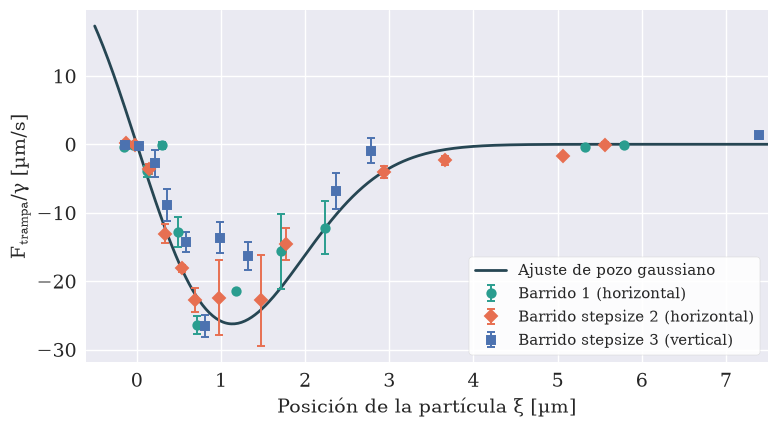

In [3]:
def mapa(f, bordes):
    f = f[f.fase != "antes"]
    filas = []
    for a, b in zip(bordes[:-1], bordes[1:]):
        g = f[(f.xi_um >= a) & (f.xi_um < b)]
        if len(g) < 2:
            continue
        mad = 1.4826 * np.median(np.abs(g.u_par_um_s - g.u_par_um_s.median()))
        filas.append(dict(xi_um=g.xi_um.mean(), u_um_s=g.u_par_um_s.median(), err_u_um_s=max(mad, 0.3) / np.sqrt(len(g)), n=len(g)))
    return pd.DataFrame(filas)


BORDES = np.r_[-0.5, -0.1, 0.1, 0.25, 0.45, 0.65, 0.85, 1.1, 1.5, 2.0, 2.6, 3.3, 4.2, 5.5, 7.5]
en_x = inter[inter.eje == "x"]
# (grabación, eje de las patadas, color, marcador, etiqueta)
grupos = (("BARRIDO 1", "x", SERIE1, "o", "Barrido 1 (horizontal)"), ("BARRIDO STEPSIZE 2", "x", SERIE2, "D", "Barrido stepsize 2 (horizontal)"),
          ("BARRIDO STEPSIZE 3", "y", AZUL, "s", "Barrido stepsize 3 (vertical)"))
global_x = ajustar_pozo(en_x[en_x.grabacion.isin(["BARRIDO 1", "BARRIDO STEPSIZE 2"])])
fig, ax = plt.subplots(figsize=(8, 4.5))
tablas = []
for k, (nombre, eje, color, fmt, etiqueta) in enumerate(grupos):
    m = mapa(inter[(inter.grabacion == nombre) & (inter.eje == eje)], BORDES)
    m.insert(0, "grabacion", nombre)
    m.insert(1, "eje", eje)
    tablas.append(m)
    ax.errorbar(m.xi_um + 0.03 * (k - 1), m.u_um_s, m.err_u_um_s, fmt=fmt, ms=6, capsize=3, elinewidth=1.4, capthick=1.4, mew=1.4,
                color=color, mfc=color, mec=color, zorder=3, label=etiqueta)
xx = np.linspace(-0.5, 7.5, 400)
ax.plot(xx, fuerza_modelo(xx, global_x["k"], global_x["w"]), color=AJUSTE, lw=2, zorder=2, label="Ajuste de pozo gaussiano")
ax.set_xlabel(r"Posición de la partícula $\xi$ [µm]")
ax.set_ylabel(r"$F_\mathrm{trampa}/\gamma$ [µm/s]")
ax.set_xlim(-0.6, 7.5)
ax.legend(loc="lower right", fontsize=11, facecolor="white", framealpha=0.9)
guardar(fig, "mapa_de_fuerza")
os.makedirs(os.path.join(DATOS, "pinzas"), exist_ok=True)
pd.concat(tablas).to_csv(os.path.join(DATOS, "pinzas", "pozo_mapa.csv"), index=False, float_format="%.4g")
pd.concat(tablas).round(2)

## 3. Ajuste de un pozo gaussiano

Modelo: un pozo de potencial gaussiano,

$$U(\xi) = -U_0\, e^{-\xi^2/2w^2}, \qquad \frac{F}{\gamma} = u(\xi) = -k\,\xi\, e^{-\xi^2/2w^2}, \qquad k = \frac{\kappa}{\gamma} = \frac{1}{\tau_c}, \qquad U_0 = \gamma\,k\,w^2 .$$

Cerca del centro es un resorte de rigidez $\kappa = \gamma k$; la fuerza es máxima en $\xi = w$ y vale $\gamma\,k\,w\,e^{-1/2}$. $k$ es la inversa del tiempo de relajación $\tau_c$ (la «frecuencia» de la trampa: $f_c = k/2\pi$).

**Cómo se ajusta.** No sobre el mapa promediado, sino intervalo por intervalo: se integra $\dot\xi = v_f + u(\xi)$ desde la posición del primer cuadro durante $\Delta t$ y se compara dónde tendría que terminar la partícula con dónde terminó. Así no se supone que la fuerza es constante mientras la partícula recorre varios µm. El error sale de remuestrear patadas enteras (bootstrap).

In [4]:
NOTAS = {"BARRIDO 2": "tres de las cuatro partículas atrapadas son chicas (radio aparente 1.05 µm): no comparable",
         "BARRIDO STEPSIZE": "las seis patadas la sacan de la trampa: no hay vueltas que fijen el pozo, ajuste no confiable",
         "MUEVO A MANO": "platina movida a mano: movimientos largos e irregulares"}
filas = []
for nombre in CON_PATADAS:
    if nombre == "LASER NE":            # sus «patadas» son una deriva lenta que no aparta a la partícula: no hay nada que ajustar
        continue
    for eje in "xy":
        g = inter[(inter.grabacion == nombre) & (inter.eje == eje)]
        if g.patada.nunique() < 4:
            continue
        r = ajustar_pozo(g)
        filas.append(dict(grabacion=nombre, eje=eje, **r, nota=NOTAS.get(nombre, "")))
aj = pd.DataFrame(filas)
aj["tau_c_ms"] = 1000 / aj.k
aj["f_c_Hz"] = aj.k / (2 * np.pi)
aj.to_csv(os.path.join(DATOS, "pinzas", "pozo_ajustes.csv"), index=False, float_format="%.4g")
print("ajuste conjunto de las patadas horizontales de BARRIDO 1 y BARRIDO STEPSIZE 2:")
print("  k = %.1f ± %.1f 1/s  (tau_c = %.1f ms, f_c = %.1f Hz)   w = %.2f ± %.2f µm   u_max = %.1f ± %.1f µm/s   k·w² = %.0f ± %.0f µm²/s   (%d patadas)"
      % (global_x["k"], global_x["err_k"], 1000 / global_x["k"], global_x["k"] / (2 * np.pi), global_x["w"], global_x["err_w"],
         global_x["u_max"], global_x["err_u_max"], global_x["k_w2"], global_x["err_k_w2"], global_x["n_patadas"]))
buenos = aj[aj.nota == ""]
print("grabaciones sin reparos (%s): k de %.0f a %.0f 1/s, w de %.2f a %.2f µm, u_max de %.0f a %.0f µm/s"
      % (", ".join(buenos.grabacion + " " + buenos.eje), buenos.k.min(), buenos.k.max(), buenos.w.min(), buenos.w.max(), buenos.u_max.min(), buenos.u_max.max()))
v3 = aj[aj.grabacion == "BARRIDO STEPSIZE 3"].set_index("eje")
if len(v3) == 2:
    print("BARRIDO STEPSIZE 3, vertical / horizontal: k %.2f ± %.2f, w %.2f ± %.2f"
          % (v3.k["y"] / v3.k["x"], v3.k["y"] / v3.k["x"] * np.hypot(v3.err_k["y"] / v3.k["y"], v3.err_k["x"] / v3.k["x"]),
             v3.w["y"] / v3.w["x"], v3.w["y"] / v3.w["x"] * np.hypot(v3.err_w["y"] / v3.w["y"], v3.err_w["x"] / v3.w["x"])))
aj[["grabacion", "eje", "n_patadas", "n_intervalos", "k", "err_k", "tau_c_ms", "f_c_Hz", "w", "err_w", "u_max", "err_u_max", "k_w2", "err_k_w2", "residuo_um", "nota"]].round(2)

ajuste conjunto de las patadas horizontales de BARRIDO 1 y BARRIDO STEPSIZE 2:
  k = 38.1 ± 4.2 1/s  (tau_c = 26.3 ms, f_c = 6.1 Hz)   w = 1.14 ± 0.09 µm   u_max = 26.3 ± 2.0 µm/s   k·w² = 49 ± 6 µm²/s   (23 patadas)
grabaciones sin reparos (BARRIDO 1 x, BARRIDO STEPSIZE 2 x, BARRIDO STEPSIZE 3 x, BARRIDO STEPSIZE 3 y): k de 32 a 39 1/s, w de 0.93 a 1.19 µm, u_max de 19 a 27 µm/s
BARRIDO STEPSIZE 3, vertical / horizontal: k 1.17 ± 0.50, w 0.93 ± 0.28


,grabacion,eje,n_patadas,n_intervalos,k,err_k,tau_c_ms,f_c_Hz,w,err_w,u_max,err_u_max,k_w2,err_k_w2,residuo_um,nota
0,BARRIDO 1,x,12,237,38.00,7.55,26.32,6.05,1.19,0.13,27.39,3.97,53.65,11.27,0.07,
1,MUEVO A MANO,x,8,175,47.06,8.42,21.25,7.49,1.02,0.15,29.11,4.04,48.95,10.65,0.24,platina movida a mano: movimientos largos e ir...
2,BARRIDO 2,x,10,240,139.34,192.91,7.18,22.18,0.27,0.05,22.52,42.21,9.89,24.90,0.08,tres de las cuatro partículas atrapadas son ch...
3,BARRIDO STEPSIZE,x,6,94,5.16,7.90,193.93,0.82,2.12,2.18,6.64,13.20,23.28,149.75,0.15,las seis patadas la sacan de la trampa: no hay...
4,BARRIDO STEPSIZE 2,x,11,242,38.78,4.21,25.79,6.17,1.08,0.11,25.34,2.47,45.00,7.66,0.07,
5,BARRIDO STEPSIZE 3,x,10,245,31.64,9.57,31.60,5.04,1.00,0.24,19.12,3.62,31.42,4.69,0.14,
6,BARRIDO STEPSIZE 3,y,17,323,36.95,11.01,27.06,5.88,0.93,0.17,20.85,3.96,31.97,5.68,0.15,


### ¿Se le puede creer al ajuste? Prueba con patadas inventadas

Se simulan patadas triangulares (aceleración constante hasta la mitad y frenado) con un pozo gaussiano conocido, se muestrean como la cámara (posición promediada durante la exposición, tomada igual al tiempo entre cuadros, más ruido de localización) y se ajustan con el mismo código.

In [5]:
def patadas_sinteticas(k, w, n_pat=12, dt=0.08, ruido=0.04, fino=200, semilla=1):
    rng = np.random.default_rng(semilla)
    filas = []
    for p in range(n_pat):
        d, T, t0 = rng.uniform(3, 11), rng.uniform(0.22, 0.42), rng.uniform(0, dt)      # desplazamiento [µm], duración [s]
        h = dt / fino
        t = np.arange(-0.3, T + 1.6, h)
        vf = np.where((t > t0) & (t < t0 + T), (4 * d / T ** 2) * np.minimum(t - t0, t0 + T - t), 0.0)
        xi = np.zeros(len(t))
        for i in range(len(t) - 1):
            xi[i + 1] = xi[i] + h * (vf[i] + fuerza_modelo(xi[i], k, w))
        S = np.cumsum(vf) * h
        nq = len(t) // fino
        xm = xi[:nq * fino].reshape(nq, fino).mean(1) + rng.normal(0, ruido, nq)
        Sm = S[:nq * fino].reshape(nq, fino).mean(1) + rng.normal(0, 0.03, nq)
        for i in range(nq - 1):
            filas.append(dict(grabacion="sint", patada=p, xi_ini_um=xm[i], xi_fin_um=xm[i + 1], vf_um_s=(Sm[i + 1] - Sm[i]) / dt, dt_s=dt))
    return pd.DataFrame(filas)


prueba = []
for k, w in ((38, 1.1), (20, 1.5), (60, 0.9), (38, 2.0)):
    r = ajustar_pozo(patadas_sinteticas(k, w), n_boot=60)
    prueba.append({"k verdadero": k, "k ajustado": r["k"], "w verdadero": w, "w ajustado": r["w"],
                   "u_max verdadero": k * w * np.exp(-0.5), "u_max ajustado": r["u_max"]})
prueba = pd.DataFrame(prueba)
print("sesgo de k: de %+.0f a %+.0f %% | de w: de %+.0f a %+.0f %% | de u_max: de %+.0f a %+.0f %%"
      % (100 * (prueba["k ajustado"] / prueba["k verdadero"] - 1).min(), 100 * (prueba["k ajustado"] / prueba["k verdadero"] - 1).max(),
         100 * (prueba["w ajustado"] / prueba["w verdadero"] - 1).min(), 100 * (prueba["w ajustado"] / prueba["w verdadero"] - 1).max(),
         100 * (prueba["u_max ajustado"] / prueba["u_max verdadero"] - 1).min(), 100 * (prueba["u_max ajustado"] / prueba["u_max verdadero"] - 1).max()))
prueba.round(2)

sesgo de k: de -5 a +1 % | de w: de -4 a -1 % | de u_max: de -8 a -4 %


,k verdadero,k ajustado,w verdadero,w ajustado,u_max verdadero,u_max ajustado
0,38,36.47,1.1,1.07,25.35,23.69
1,20,18.92,1.5,1.49,18.20,17.08
2,60,57.61,0.9,0.86,32.75,30.16
3,38,38.37,2.0,1.91,46.10,44.47


## 4. ¿Cuándo se escapa?

Cada patada confiable que empezó con una partícula atrapada, según cuánto desplazó la imagen y con qué velocidad pico (promediada por cuadro), y qué hizo la partícula. La curva es lo que predice el pozo ajustado para una patada triangular de la duración típica: por encima, la partícula no vuelve.

29 patadas: 10 se escapan, 19 vuelven o no se apartan
se escapan: desplazamiento de 1.7 a 24.5 µm, velocidad pico de 9 a 92 µm/s
no se escapan: desplazamiento de 1.9 a 8.8 µm, velocidad pico de 10 a 37 µm/s
pozo ajustado, patada triangular de 0.30 s: se escapa si desplaza más de 7.5 µm (pico real de 50 µm/s)
apartamiento máximo del que volvió sola: 5.6 µm (BARRIDO STEPSIZE 2, patada 4, tardó 1.7 s)
escapes con patadas chicas (menos de 6 µm): BARRIDO 1 n=7 (5.4 µm, 26 µm/s), BARRIDO STEPSIZE n=8 (3.1 µm, 20 µm/s), BARRIDO STEPSIZE n=15 (1.7 µm, 9 µm/s)
BARRIDO 2 (partículas chicas): se escapan con 2.3, 3.0, 8.3, 20.0 µm; vuelven con 0.8, 1.0, 2.3, 3.8, 5.2, 8.4, 15.4 µm


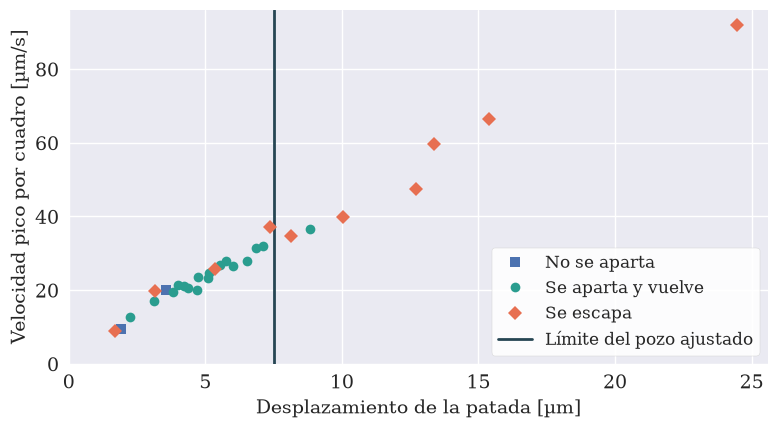

In [6]:
def se_escapa(d, T, k, w, h=0.002):
    # patada triangular de desplazamiento d [µm] y duración T [s]: ¿la partícula queda fuera del pozo 2 s después?
    t = np.arange(0, T + 2.0, h)
    vf = np.where(t < T, (4 * d / T ** 2) * np.minimum(t, T - t), 0.0)
    xi = 0.0
    for v in vf:
        xi += h * (v + float(fuerza_modelo(xi, k, w)))
    return xi > 0.5


todas = utiles[utiles.grabacion != "LASER NE"].copy()
todas["desplazamiento_um"] = np.hypot(todas.dx_um, todas.dy_um)
todas.to_csv(os.path.join(DATOS, "pinzas", "fuerza_resumen.csv"), index=False, float_format="%.5g")
# para la figura: patadas del motor, horizontales, con partículas de tamaño nominal (BARRIDO 2 atrapó partículas chicas)
u = todas[todas.grabacion.isin(["BARRIDO 1", "BARRIDO STEPSIZE", "BARRIDO STEPSIZE 2"]) & (todas.dx_um.abs() > todas.dy_um.abs())].copy()
fig, ax = plt.subplots(figsize=(8, 4.5))
for res, color, fmt, etiqueta in (("no se aparto", AZUL, "s", "No se aparta"), ("se aparto y volvio", SERIE1, "o", "Se aparta y vuelve"), ("escapo", SERIE2, "D", "Se escapa")):
    g = u[u.resultado == res]
    ax.plot(g.desplazamiento_um, g.v_pico_um_s, fmt, ms=7, color=color, mec=color, zorder=3, label=etiqueta)
T_tip = float(u.duracion_s.median())
d_crit = next((d for d in np.arange(1.0, 30.0, 0.25) if se_escapa(d, T_tip, global_x["k"], global_x["w"])), np.nan)
ax.axvline(d_crit, color=AJUSTE, lw=2, zorder=2, label="Límite del pozo ajustado")
ax.set_xlabel("Desplazamiento de la patada [µm]")
ax.set_ylabel("Velocidad pico por cuadro [µm/s]")
ax.set_xlim(0, None); ax.set_ylim(0, None)
ax.legend(loc="lower right", fontsize=12, facecolor="white", framealpha=0.9)
guardar(fig, "escape")
esc, ret = u[u.resultado == "escapo"], u[u.resultado != "escapo"]
print("%d patadas: %d se escapan, %d vuelven o no se apartan" % (len(u), len(esc), len(ret)))
print("se escapan: desplazamiento de %.1f a %.1f µm, velocidad pico de %.0f a %.0f µm/s" % (esc.desplazamiento_um.min(), esc.desplazamiento_um.max(), esc.v_pico_um_s.min(), esc.v_pico_um_s.max()))
print("no se escapan: desplazamiento de %.1f a %.1f µm, velocidad pico de %.0f a %.0f µm/s" % (ret.desplazamiento_um.min(), ret.desplazamiento_um.max(), ret.v_pico_um_s.min(), ret.v_pico_um_s.max()))
print("pozo ajustado, patada triangular de %.2f s: se escapa si desplaza más de %.1f µm (pico real de %.0f µm/s)" % (T_tip, d_crit, 2 * d_crit / T_tip))
print("apartamiento máximo del que volvió sola: %.1f µm (%s, patada %d, tardó %.1f s)"
      % (ret.xi_max_um.max(), ret.loc[ret.xi_max_um.idxmax(), "grabacion"], ret.loc[ret.xi_max_um.idxmax(), "n"], ret.loc[ret.xi_max_um.idxmax(), "t_vuelta_s"]))
print("escapes con patadas chicas (menos de 6 µm):", ", ".join("%s n=%d (%.1f µm, %.0f µm/s)" % (r.grabacion, r.n, r.desplazamiento_um, r.v_pico_um_s)
                                                           for r in esc[esc.desplazamiento_um < 6].itertuples()) or "ninguno")
b2 = todas[todas.grabacion == "BARRIDO 2"]
print("BARRIDO 2 (partículas chicas): se escapan con %s µm; vuelven con %s µm"
      % (", ".join("%.1f" % v for v in sorted(b2[b2.resultado == "escapo"].desplazamiento_um)),
         ", ".join("%.1f" % v for v in sorted(b2[b2.resultado != "escapo"].desplazamiento_um))))

## 5. De µm/s a pN: el coeficiente de arrastre $\gamma$

Todo lo anterior está dividido por $\gamma$. Hay tres formas de conseguirlo y **no dan lo mismo**:

1. **Receta del cuaderno + Stokes.** «60 ml de agua y 65 ml de glicerina» es 58 % de glicerina en masa: 8.4 mPa·s a 23 °C. Con $R$ = 1.5 µm, $\gamma = 6\pi\eta R$.
2. **Las partículas libres de las mismas grabaciones.** En los dos barridos de potencia la platina no se mueve y hay partículas libres de tamaño nominal en el campo, en la misma muestra y al mismo tiempo que la atrapada. Su coeficiente de difusión da $\gamma = k_BT/D$ (Einstein) sin suponer viscosidad ni radio. Es lo que pidió Lenny: comparar con las partículas no pinzadas en vez de confiar en valores nominales.
3. **La misma partícula atrapada, cuando la trampa casi no la retiene.** Al final de `BARRIDO POTENCIAS 2` (potencia por debajo de 3 mW) la partícula deambula a varios µm del centro. A tiempos cortos difunde casi libre: la pendiente inicial de su MSD da su propio $D$, a la altura a la que la deja la trampa.

Se usa la 2 como valor central y la 3 como control. La 1 queda como comparación: la difusión medida es unas 5 veces más rápida que la que daría esa receta (ver `DUDAS pinzas.md`).


1. receta: 58 % de glicerina en masa, 8.4 mPa·s → gamma = 2.36e-07 N·s/m (D esperado 0.017 µm²/s)
2. 22 partículas libres de tamaño nominal: D = 0.082 ± 0.004 µm²/s → gamma = 4.98e-08 ± 2.4e-09 N·s/m
   por grabación: BARRIDO POTENCIAS 2 0.072 (n=9), LASER 5 0.089 (n=13)
3. la atrapada casi suelta (622 cuadros): D = 0.074 µm²/s → gamma = 5.55e-08 N·s/m
   cociente gamma receta / gamma libres = 4.7

con gamma de las partículas libres:  kappa = 1.9 ± 0.2 pN/µm   F_max = 1.31 ± 0.12 pN   U0 = 600 ± 77 kT


,gamma de,gamma [1e-8 N·s/m],rigidez kappa [pN/µm],fuerza máxima [pN],profundidad del pozo [kT],sigma térmica esperada [nm]
0,partículas libres (central),4.983,1.898,1.308,599.527,46.412
1,atrapada casi suelta,5.549,2.113,1.457,667.521,43.985
2,receta + Stokes,23.617,8.996,6.200,2841.177,21.320


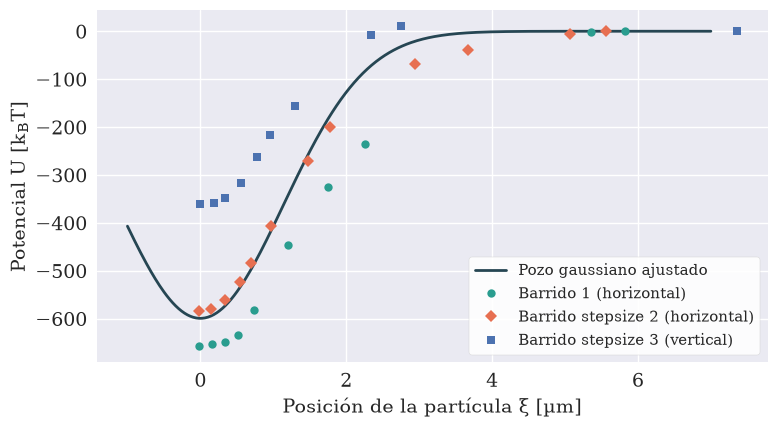

In [7]:
import trayectorias as T
from pinzas import fisica, libre

# --- 1. receta del cuaderno + Stokes
masa_glicerina, masa_agua = 65 * 1.261, 60 * 0.998          # g (densidades a 20 °C)
fraccion = masa_glicerina / (masa_glicerina + masa_agua)
eta_receta = float(fisica.viscosidad_glicerina_agua(fraccion, 296.15))
gamma_receta = fisica.gamma_stokes(eta_receta, 1.5e-6)

# --- 2. partículas libres de tamaño nominal en los barridos de potencia
filas = []
for nombre in ("LASER 5", "BARRIDO POTENCIAS 2"):
    datos = T.cargar(os.path.join(DATOS, nombre))
    datos["tr"].loc[datos["tr"].colision == 1, ["x_px", "y_px"]] = np.nan
    t, X, Y, ids, _ = T.matrices(datos, escala_um=ESCALA_UM, largo_min=300)
    Xs, Ys = T.sin_deriva_por_particula(t, X, Y)
    m = T.msd(t, Xs, Ys, 20)
    alfa, tab = T.pendiente_loglog(m), T.coeficientes_D(m, n_puntos=4)
    radios = pd.read_csv(os.path.join(DATOS, nombre, "radios.csv")).set_index("particula")
    tx, ty = CATALOGO[nombre]["trampa_px"]
    for k, p in enumerate(ids):
        filas.append(dict(grabacion=nombre, particula=p, cuadros=int(np.isfinite(X[:, k]).sum()),
                          distancia_a_la_trampa_um=np.hypot(np.nanmean(X[:, k]) - tx * ESCALA_UM, np.nanmean(Y[:, k]) - ty * ESCALA_UM),
                          alfa=alfa[k], D_um2_s=tab.D[k], radio_aparente_um=radios.r_borde_px.get(p, np.nan) * ESCALA_UM))
lib = pd.DataFrame(filas)
lib["nominal_y_libre"] = (lib.distancia_a_la_trampa_um > 8) & (lib.alfa > 0.7) & (lib.radio_aparente_um > 1.5) & (lib.radio_aparente_um < 2.3)
sel = lib[lib.nominal_y_libre]
D_libres, err_D_libres = sel.D_um2_s.mean(), sel.D_um2_s.std(ddof=1) / np.sqrt(len(sel))
gamma_libres = KB_T / (D_libres * 1e-12)
err_gamma_libres = gamma_libres * err_D_libres / D_libres
lib.to_csv(os.path.join(DATOS, "pinzas", "difusion_libres_en_trampa.csv"), index=False, float_format="%.4g")

# --- 3. la partícula atrapada, casi suelta (BARRIDO POTENCIAS 2, potencia < 3 mW)
a = pd.read_csv(os.path.join(DATOS, "BARRIDO POTENCIAS 2", "atrapada.csv"))
s = a[(a.t_s > 155) & (a.t_s < 210) & a.particula.notna()]
ms = libre.msd(s.t_s.values, s.x_um.values, s.y_um.values, max_lag=8)
aj_s = libre.ajustar_msd(ms["tau"], ms["msd"][:, 0], 0.0, n_puntos=4)
D_suelta = aj_s["D"]
gamma_suelta = KB_T / (D_suelta * 1e-12)

print("1. receta: %.0f %% de glicerina en masa, %.1f mPa·s → gamma = %.2e N·s/m (D esperado %.3f µm²/s)"
      % (100 * fraccion, eta_receta * 1e3, gamma_receta, KB_T / gamma_receta * 1e12))
print("2. %d partículas libres de tamaño nominal: D = %.3f ± %.3f µm²/s → gamma = %.2e ± %.1e N·s/m"
      % (len(sel), D_libres, err_D_libres, gamma_libres, err_gamma_libres))
print("   por grabación:", ", ".join("%s %.3f (n=%d)" % (n, g.D_um2_s.mean(), len(g)) for n, g in sel.groupby("grabacion")))
print("3. la atrapada casi suelta (%d cuadros): D = %.3f µm²/s → gamma = %.2e N·s/m" % (len(s), D_suelta, gamma_suelta))
print("   cociente gamma receta / gamma libres = %.1f" % (gamma_receta / gamma_libres))

# --- resultados en pN
k, w, u_max, kw2 = global_x["k"], global_x["w"], global_x["u_max"], global_x["k_w2"]
filas = []
for nombre, g in (("partículas libres (central)", gamma_libres), ("atrapada casi suelta", gamma_suelta), ("receta + Stokes", gamma_receta)):
    filas.append({"gamma de": nombre, "gamma [1e-8 N·s/m]": g * 1e8, "rigidez kappa [pN/µm]": g * k * 1e6, "fuerza máxima [pN]": g * u_max * 1e-6 * 1e12,
                  "profundidad del pozo [kT]": g * kw2 * 1e-12 / KB_T, "sigma térmica esperada [nm]": 1e9 * np.sqrt(KB_T / (g * k))})
fuerza = pd.DataFrame(filas)
fuerza.to_csv(os.path.join(DATOS, "pinzas", "fuerza_en_pN.csv"), index=False, float_format="%.4g")
err_rel = np.hypot(global_x["err_u_max"] / u_max, err_gamma_libres / gamma_libres)
print("\ncon gamma de las partículas libres:  kappa = %.1f ± %.1f pN/µm   F_max = %.2f ± %.2f pN   U0 = %.0f ± %.0f kT"
      % (gamma_libres * k * 1e6, gamma_libres * k * 1e6 * np.hypot(global_x["err_k"] / k, err_gamma_libres / gamma_libres),
         gamma_libres * u_max * 1e6, gamma_libres * u_max * 1e6 * err_rel,
         gamma_libres * kw2 * 1e-12 / KB_T, gamma_libres * kw2 * 1e-12 / KB_T * np.hypot(global_x["err_k_w2"] / kw2, err_gamma_libres / gamma_libres)))

# --- el pozo en kT (con gamma de las libres)
xx = np.linspace(-1, 7, 400)
U = -gamma_libres * kw2 * 1e-12 / KB_T * np.exp(-xx ** 2 / (2 * w ** 2))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(xx, U, color=AJUSTE, lw=2, zorder=2, label="Pozo gaussiano ajustado")
m = pd.read_csv(os.path.join(DATOS, "pinzas", "pozo_mapa.csv"))
for nombre, eje, color, fmt, etiqueta in grupos:                       # integral del mapa medido, desde afuera hacia el centro
    g = m[(m.grabacion == nombre) & (m.eje == eje) & (m.xi_um > -0.05)].sort_values("xi_um")
    if len(g) < 4:
        continue
    x_, u_ = g.xi_um.values, g.u_um_s.values
    Um = np.r_[0, np.cumsum(0.5 * (u_[1:] + u_[:-1]) * np.diff(x_))]          # ∫ u dξ desde el primer punto
    Um = -(Um - Um[-1]) * gamma_libres * 1e-12 / KB_T                        # U(ξ) = −∫_ξ^∞ F dξ', con U(∞) = 0
    ax.plot(x_, Um, fmt, ms=6, color=color, mec=color, zorder=3, label=etiqueta)
ax.set_xlabel(r"Posición de la partícula $\xi$ [µm]")
ax.set_ylabel(r"Potencial $U$ [$k_BT$]")
ax.legend(loc="lower right", fontsize=11, facecolor="white", framealpha=0.9)
guardar(fig, "pozo_de_potencial")
fuerza.round(3)


## 6. Dos controles

**¿Coincide con el movimiento térmico?** `PINZAS 4` mide la rigidez por otro camino, que no usa ni la platina ni el arrastre: con la partícula quieta, $\kappa = k_BT/\sigma^2$ (equipartición). Si las dos rigideces coinciden, el arrastre elegido es el correcto. Además, dividiendo la rigidez térmica por $k = \kappa/\gamma$ del arrastre sale un $\gamma$ que no depende de ninguna medición de difusión.

**¿Molesta el láser al medir la posición?** `PINZAS 4` encontró que la cámara le resta rojo al verde y que el láser deja un punto oscuro en el centro de la partícula atrapada, que corre la posición medida cuando la partícula se aparta poco. Se repitió la detección de `BARRIDO 1` y `BARRIDO STEPSIZE 2` rellenando un disco de 11 px en el láser antes de localizar (`trampa_roi.py --tapar=11`) y se volvió a ajustar el pozo.


In [8]:
from pinzas_datos import atrapada, patadas
from pinzas_fuerza import seguir, intervalos

# --- rigidez térmica (PINZAS 4) contra rigidez por arrastre, a 30 mW y en x
esc = pd.read_csv(os.path.join(DATOS, "pinzas", "potencia_escalones.csv"))
e30 = esc[(esc.escalon == 1) & (esc.eje == "x")]
filas = []
for r in e30.itertuples():
    filas.append({"grabación": r.grabacion, "kappa térmica [pN/µm] (W = dt/2)": r.kappa_equiparticion, "error": r.err_kappa_total,
                  "si W = 0": r.kappa_equiparticion_W0, "si W = dt": r.kappa_equiparticion_Wdt,
                  "gamma = kappa térmica / k [1e-8 N·s/m]": r.kappa_equiparticion * 1e-6 / k * 1e8})
termica = pd.DataFrame(filas)
kappa_arrastre = gamma_libres * k * 1e6
err_kappa_arrastre = kappa_arrastre * np.hypot(global_x["err_k"] / k, err_gamma_libres / gamma_libres)
pesos = 1 / termica["error"] ** 2
kappa_termica = float((termica["kappa térmica [pN/µm] (W = dt/2)"] * pesos).sum() / pesos.sum())
print("rigidez por arrastre (gamma de las libres):  %.2f ± %.2f pN/µm" % (kappa_arrastre, err_kappa_arrastre))
print("rigidez térmica (promedio pesado de las dos grabaciones, W = dt/2):  %.2f pN/µm   (de %.1f con W = dt a %.1f con W = 0)"
      % (kappa_termica, termica["si W = dt"].min(), termica["si W = 0"].max()))
print("gamma que cierra las dos:  %.1f × 10⁻⁸ N·s/m   (libres: %.1f; atrapada casi suelta: %.1f; receta: %.1f)"
      % (kappa_termica * 1e-6 / k * 1e8, gamma_libres * 1e8, gamma_suelta * 1e8, gamma_receta * 1e8))

# --- control del punto oscuro del láser
tablas = []
for nombre in ("BARRIDO 1", "BARRIDO STEPSIZE 2"):
    if not os.path.exists(os.path.join(DATOS, nombre, "trampa_detecciones_tapado.csv")):
        continue
    a = atrapada(nombre)
    f = intervalos(nombre, seguida=seguir(nombre, tabla=a, detecciones="trampa_detecciones_tapado.csv"), tabla_patadas=patadas(nombre, tabla=a))
    tablas.append(f[f.e_x.abs() >= f.e_y.abs()])
if tablas:
    tapado = ajustar_pozo(pd.concat(tablas))
    print("\npozo con el núcleo del láser tapado:  k = %.1f ± %.1f 1/s   w = %.2f ± %.2f µm   u_max = %.1f ± %.1f µm/s   k·w² = %.0f ± %.0f µm²/s"
          % (tapado["k"], tapado["err_k"], tapado["w"], tapado["err_w"], tapado["u_max"], tapado["err_u_max"], tapado["k_w2"], tapado["err_k_w2"]))
    print("sin tapar (el de arriba):             k = %.1f ± %.1f 1/s   w = %.2f ± %.2f µm   u_max = %.1f ± %.1f µm/s   k·w² = %.0f ± %.0f µm²/s"
          % (k, global_x["err_k"], w, global_x["err_w"], u_max, global_x["err_u_max"], kw2, global_x["err_k_w2"]))
    print("cambio: k %+.0f %%, w %+.0f %%, u_max %+.0f %%" % (100 * (tapado["k"] / k - 1), 100 * (tapado["w"] / w - 1), 100 * (tapado["u_max"] / u_max - 1)))
termica.round(2)


rigidez por arrastre (gamma de las libres):  1.90 ± 0.23 pN/µm
rigidez térmica (promedio pesado de las dos grabaciones, W = dt/2):  2.03 pN/µm   (de 1.6 con W = dt a 3.2 con W = 0)
gamma que cierra las dos:  5.3 × 10⁻⁸ N·s/m   (libres: 5.0; atrapada casi suelta: 5.5; receta: 23.6)



pozo con el núcleo del láser tapado:  k = 34.6 ± 2.4 1/s   w = 1.21 ± 0.06 µm   u_max = 25.3 ± 1.2 µm/s   k·w² = 50 ± 3 µm²/s
sin tapar (el de arriba):             k = 38.1 ± 4.2 1/s   w = 1.14 ± 0.09 µm   u_max = 26.3 ± 2.0 µm/s   k·w² = 49 ± 6 µm²/s
cambio: k -9 %, w +6 %, u_max -4 %


,grabación,kappa térmica [pN/µm] (W = dt/2),error,si W = 0,si W = dt,gamma = kappa térmica / k [1e-8 N·s/m]
0,LASER 5,2.03,0.20,3.00,1.65,5.32
1,BARRIDO POTENCIAS 2,2.11,0.68,3.23,1.70,5.54


## Conclusión

**Forma del pozo (sin suponer nada sobre el fluido).** La fuerza de la trampa es restitutiva y lineal cerca del centro, llega a un máximo a 1.1 µm y se anula pasados unos 3.5 µm. Un pozo gaussiano describe bien las patadas horizontales de `BARRIDO 1` y `BARRIDO STEPSIZE 2`, que son dos grabaciones independientes:

| Magnitud | Valor |
|---|---|
| $k = \kappa/\gamma$ | 38 ± 4 s⁻¹ |
| Tiempo de relajación $\tau_c = 1/k$ | 26 ms |
| Frecuencia de esquina $f_c = k/2\pi$ | 6.1 Hz |
| Ancho del pozo $w$ (donde la fuerza es máxima) | 1.14 ± 0.09 µm |
| Fuerza máxima / $\gamma$ | 26 ± 2 µm/s |

- **Vertical contra horizontal** (`BARRIDO STEPSIZE 3`): los ajustes coinciden dentro del error, que es grande (25 a 30 %). No se ve anisotropía, pero tampoco se puede descartar una menor a ese error.
- **Sesgo del método**, medido con patadas simuladas: $k$ sale hasta 5 % por debajo, $w$ hasta 4 % y la fuerza máxima hasta 8 %.
- **Alcance:** la partícula volvió sola desde 5.6 µm del centro (tardó 1.7 s), así que la trampa atrae, débilmente, más lejos de lo que marca la gaussiana.

**En unidades de fuerza.** Con el arrastre medido en las partículas libres de la misma muestra ($D$ = 0.082 ± 0.004 µm²/s, $\gamma$ = 5.0 × 10⁻⁸ N·s/m), a 30 mW:

| Magnitud | Con $\gamma$ de las partículas libres | Con la receta del cuaderno |
|---|---|---|
| Rigidez $\kappa$ | 1.9 ± 0.2 pN/µm | 9.0 pN/µm |
| Fuerza máxima | 1.3 ± 0.1 pN | 6.2 pN |
| Profundidad del pozo | 600 ± 80 $k_BT$ | 2800 $k_BT$ |

Los errores de la primera columna son estadísticos. Tres controles independientes sostienen ese arrastre y descartan la receta del cuaderno:

- **La misma partícula atrapada**, cuando la trampa casi no la retiene, difunde con $D$ = 0.074 µm²/s: 11 % más de arrastre que las libres.
- **El movimiento térmico** (`PINZAS 4`, que no usa platina ni arrastre) da una rigidez de 2.0 pN/µm a 30 mW suponiendo una exposición de medio período, y entre 1.6 y 3.2 según la exposición. Por arrastre sale 1.9 ± 0.2.
- **El arrastre que hace coincidir las dos rigideces** es 5.3 × 10⁻⁸ N·s/m, contra 5.0 de las libres y 23.6 de la receta.

**El punto oscuro del láser** (la cámara le resta rojo al verde) corre la posición medida entre 0.1 y 0.25 µm cuando la partícula está a menos de 2 µm del centro. Repitiendo todo con el núcleo del láser tapado, $k$ baja 9 %, $w$ sube 6 % y la fuerza máxima baja 4 %: menos que el error estadístico. Queda como incerteza sistemática de ese orden.

**Cuándo se escapa.** Con partículas de tamaño nominal, las patadas del motor que corren la imagen más de unos 8 µm (pico de unos 35 µm/s por cuadro) la sacan; por debajo vuelve. El pozo ajustado predice el límite en 7.5 µm para una patada de 0.30 s. Lo que manda es la velocidad, no el desplazamiento: en `BARRIDO 2` una patada lenta de 15 µm no la sacó. Hay tres escapes con patadas chicas que el pozo no explica (ver la salida de la sección 4).

**Lo que este análisis no alcanza a decir**

- **Por qué la receta del cuaderno no coincide con la muestra.** La difusión medida y la receta difieren en un factor 4.7, y los tres controles apoyan la difusión. La forma del pozo y $\tau_c$ no dependen de eso.
- **La exposición de la cámara**, que no está en los archivos: es lo que más pesa en la rigidez térmica con la que se compara.
- **La forma fina del pozo.** Con 2 a 5 cuadros por patada, cada punto del mapa promedia la fuerza sobre un tramo de varios µm. El ajuste integra el movimiento para corregirlo, pero supone que el pozo es gaussiano.
- **La fuerza a lo largo del eje del láser** (vertical respecto del vidrio): todo esto es en el plano de la imagen.
- **La altura de la partícula sobre el vidrio**, que cambia el arrastre (Faxén).
- **`BARRIDO 2`, `BARRIDO STEPSIZE` y `LASER NE` no dan un ajuste confiable**: partículas chicas, todas las patadas con escape, y solo una deriva lenta, respectivamente.

Rigidez contra potencia, frecuencia de esquina y forma del pozo cerca del centro: `PINZAS 4`.
